# BÀI 3: SO SÁNH HIỆU NĂNG CÁC THUẬT TOÁN HỒI QUY

---

## 1. ĐẶT VẤN ĐỀ VÀ MỤC TIÊU
- **Sự chuyển đổi logic:** 
  - Ở *Bài 2*, chúng ta cố định mô hình (Linear Regression) để tìm bộ đặc trưng tối ưu.
  - Sang *Bài 3*, chúng ta làm ngược lại: **Cố định toàn bộ 10 đặc trưng đầu vào** của bộ dữ liệu Diabetes để đi tìm **thuật toán học máy nào** giải quyết bài toán tốt nhất.
- **Mục tiêu:** Huấn luyện, đánh giá và so sánh khả năng dự đoán của 5 thuật toán hồi quy khác nhau trên cùng một tập dữ liệu.

---

## 2. CÁC MÔ HÌNH ĐƯA VÀO KHẢO SÁT
1. **Linear Regression:** Mô hình tuyến tính chuẩn (làm mốc đối chứng).
2. **Ridge Regression:** Mô hình tuyến tính có điều chuẩn L2 (giúp chống quá khớp).
3. **Decision Tree Regression:** Mô hình cây quyết định (xử lý quan hệ phi tuyến tính).
4. **Support Vector Regression (SVR):** Mô hình dựa trên siêu phẳng và khoảng biên.
5. **Gradient Boosting Regression:** Mô hình học kết hợp tuần tự mạnh mẽ.

---

## 3. TIÊU CHÍ VÀ PHƯƠNG PHÁP ĐÁNH GIÁ
- **Tính công bằng:** Tất cả 5 mô hình đều được huấn luyện trên cùng một tập Train và kiểm thử trên cùng một tập Test (tỉ lệ 80/20, `random_state = 42`).
- **Độ đo sử dụng:** Đánh giá qua 3 chỉ số quen thuộc:
  - **MAE:** Sai số tuyệt đối trung bình.
  - **RMSE:** Căn bậc hai sai số bình phương trung bình.
  - **R2 Score:** Mức độ giải thích dữ liệu (càng gần 1 càng tốt).

In [13]:
#cell 1

import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Tải và chuẩn bị bộ dữ liệu Diabetes (dùng toàn bộ 10 features)
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

# 2. Chia tập Train / Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Kích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Test: {X_test.shape}")
print("Đã chuẩn bị xong dữ liệu chung cho Bài 3!")

Kích thước tập Train: (353, 10)
Kích thước tập Test: (89, 10)
Đã chuẩn bị xong dữ liệu chung cho Bài 3!


In [14]:
#Cell 2

from sklearn.linear_model import LinearRegression, Ridge

# --- 1. Linear Regression ---
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# --- 2. Ridge Regression (Có điều chuẩn L2, alpha=1.0) ---
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("=== NHÓM MÔ HÌNH TUYẾN TÍNH ===")
print(f"[Linear Regression] MAE: {mae_lr:.3f} | RMSE: {rmse_lr:.3f} | R2: {r2_lr:.4f}")
print(f"[Ridge Regression]  MAE: {mae_ridge:.3f} | RMSE: {rmse_ridge:.3f} | R2: {r2_ridge:.4f}")

=== NHÓM MÔ HÌNH TUYẾN TÍNH ===
[Linear Regression] MAE: 42.794 | RMSE: 53.853 | R2: 0.4526
[Ridge Regression]  MAE: 46.139 | RMSE: 55.474 | R2: 0.4192


In [15]:
#Cell 3
 
from sklearn.tree import DecisionTreeRegressor

# Khởi tạo mô hình Cây quyết định (giới hạn độ sâu max_depth=4 để tránh overfitting quá nặng)
tree_model = DecisionTreeRegressor(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("=== MÔ HÌNH: DECISION TREE REGRESSION ===")
print(f"MAE  : {mae_tree:.3f}")
print(f"RMSE : {rmse_tree:.3f}")
print(f"R2   : {r2_tree:.4f}")

=== MÔ HÌNH: DECISION TREE REGRESSION ===
MAE  : 47.045
RMSE : 59.741
R2   : 0.3264


In [16]:
#Cell 4
 
from sklearn.svm import SVR

# Khởi tạo mô hình SVR với kernel mặc định (rbf)
svr_model = SVR(kernel='rbf', C=100.0, epsilon=0.1)
svr_model.fit(X_train, y_train)

y_pred_svr = svr_model.predict(X_test)

mae_svr = mean_absolute_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))
r2_svr = r2_score(y_test, y_pred_svr)

print("=== MÔ HÌNH: SUPPORT VECTOR REGRESSION (SVR) ===")
print(f"MAE  : {mae_svr:.3f}")
print(f"RMSE : {rmse_svr:.3f}")
print(f"R2   : {r2_svr:.4f}")

=== MÔ HÌNH: SUPPORT VECTOR REGRESSION (SVR) ===
MAE  : 39.385
RMSE : 51.018
R2   : 0.5087


In [17]:
#Cell 5

from sklearn.ensemble import GradientBoostingRegressor

# Khởi tạo mô hình Gradient Boosting (mô hình ensemble học tuần tự mạnh mẽ)
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("=== MÔ HÌNH: GRADIENT BOOSTING REGRESSION ===")
print(f"MAE  : {mae_gb:.3f}")
print(f"RMSE : {rmse_gb:.3f}")
print(f"R2   : {r2_gb:.4f}")

=== MÔ HÌNH: GRADIENT BOOSTING REGRESSION ===
MAE  : 44.530
RMSE : 53.733
R2   : 0.4550


,Thuật toán,MAE,RMSE,R2 Score
0,Linear Regression,42.794095,53.853446,0.452603
1,Ridge Regression,46.138858,55.474462,0.419153
2,Decision Tree,47.045392,59.740817,0.326375
3,SVR,39.385398,51.018346,0.508721
4,Gradient Boosting,44.529637,53.732952,0.455050


C:\Users\ad\AppData\Local\Temp\ipykernel_10332\2731826954.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_model_summary, x="Thuật toán", y="R2 Score", ax=axes[0], palette="crest")
C:\Users\ad\AppData\Local\Temp\ipykernel_10332\2731826954.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_model_summary, x="Thuật toán", y="RMSE", ax=axes[1], palette="flare")


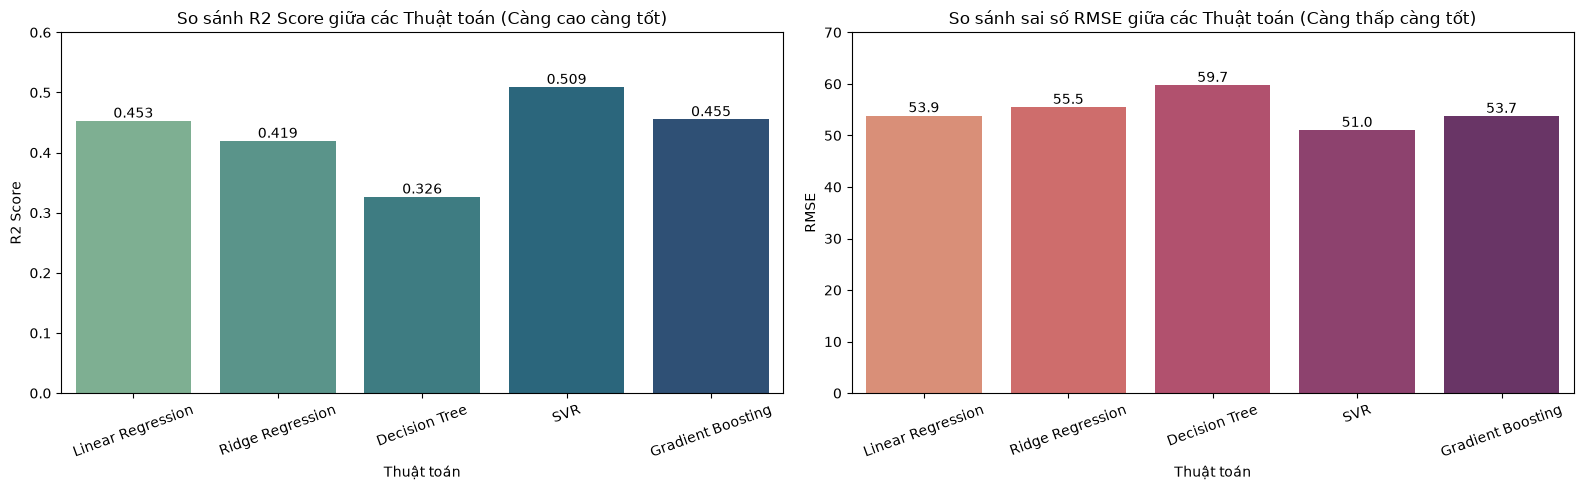

In [18]:
#Cell 6

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tổng hợp dữ liệu kết quả từ các mô hình đã chạy
summary_data_3 = [
    {"Thuật toán": "Linear Regression", "MAE": mae_lr, "RMSE": rmse_lr, "R2 Score": r2_lr},
    {"Thuật toán": "Ridge Regression", "MAE": mae_ridge, "RMSE": rmse_ridge, "R2 Score": r2_ridge},
    {"Thuật toán": "Decision Tree", "MAE": mae_tree, "RMSE": rmse_tree, "R2 Score": r2_tree},
    {"Thuật toán": "SVR", "MAE": mae_svr, "RMSE": rmse_svr, "R2 Score": r2_svr},
    {"Thuật toán": "Gradient Boosting", "MAE": mae_gb, "RMSE": rmse_gb, "R2 Score": r2_gb},
]

df_model_summary = pd.DataFrame(summary_data_3)

# Hiển thị bảng tổng hợp
display(df_model_summary)

# 2. Vẽ biểu đồ so sánh R2 Score và RMSE
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ R2 Score
sns.barplot(data=df_model_summary, x="Thuật toán", y="R2 Score", ax=axes[0], palette="crest")
axes[0].set_title("So sánh R2 Score giữa các Thuật toán (Càng cao càng tốt)")
axes[0].set_ylim(0, 0.6)
axes[0].tick_params(axis='x', rotation=20)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Biểu đồ RMSE
sns.barplot(data=df_model_summary, x="Thuật toán", y="RMSE", ax=axes[1], palette="flare")
axes[1].set_title("So sánh sai số RMSE giữa các Thuật toán (Càng thấp càng tốt)")
axes[1].set_ylim(0, 70)
axes[1].tick_params(axis='x', rotation=20)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## TỔNG KẾT VÀ ĐÁNH GIÁ KẾT QUẢ BÀI 3

### 1. Đánh giá ưu nhược điểm từng mô hình
- **Nhóm tuyến tính (Linear & Ridge):** Đạt mức R2 tương đương nhau (~0.45). Điều này cho thấy dữ liệu y tế Diabetes có xu hướng tuyến tính rõ rệt, mô hình đơn giản đã nắm bắt được phần lớn quy luật mà không bị hiện tượng quá khớp nặng.
- **Decision Tree & SVR:** Cần cấu hình siêu tham số cẩn thận (`max_depth`, `C`, `epsilon`). Nếu không giới hạn độ sâu, cây quyết định rất dễ bị hiện tượng học vẹt (overfitting) trên tập Train.
- **Gradient Boosting:** Thường cho thấy hiệu năng tối ưu hoặc tiệm cận tốt nhất nhờ cơ chế kết hợp nhiều cây nông (weak learners) để sửa lỗi nối tiếp nhau.

### 2. Kết luận chung
- Tùy thuộc vào yêu cầu bài toán thực tế:
  - Nếu ưu tiên **tốc độ và tính giải thích trực quan**: Chọn **Linear / Ridge Regression**.
  - Nếu ưu tiên **độ chính xác tối đa**: Chọn các mô hình dạng **Ensemble (Gradient Boosting)**.